# [13.5] Diffusion Transformers and ConceptAttention (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part5_dit_concept_attention/13.5_Diffusion_Transformers_and_ConceptAttention_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part5_dit_concept_attention/13.5_Diffusion_Transformers_and_ConceptAttention_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-13-5) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

Look at a red square on a gray canvas. Suppose an attention map is uniform, even though
the attention **outputs** distinguish the square from the background. Is the map uninformative,
or did we inspect the wrong representation?

By the end of this notebook, you will have shown that an output-space concept map localizes
a known square in an explicit attention organism, because segmentation IoU is1 while raw-key
attention and swapped-concept controls fail. You will implement patchification, adaptive layer
normalization, a gated DiT block and a concept stream that cannot change image outputs.

Prerequisites: attention and layer normalization from chapter1, diffusion states from13.1,
and array reshaping. The attention weights here are deliberately constructed, not trained or
pretrained. A visible finite refinement trajectory illustrates the image-state boundary; it
is not a diffusion sampler.

## Study-edition boundary

The default path is a small, deterministic CPU organism with explicit weights and finite
images. It teaches the named component operations and controls. It is not a trained diffusion
model, a pretrained checkpoint, or a paper replication. No model download, GPU selection,
training run or scientific sweep occurs. Published/native parts of the configured brief remain
pending; the bridge at the end says precisely what would need to be measured.

These are public guided exercises. Write your own prediction and prior solution exposure
before opening expected outputs. Expected outputs make this seen practice, not unseen mastery.

## Content & Learning Objectives

### 1️⃣ Images become patch tokens

Turn a small image into patch tokens and reverse the mapping exactly.

> ##### Learning Objectives
>
> - Implement the visible operations for turn a small image into patch tokens and reverse the mapping exactly.
> - Explain the tensor axes and use an independent small-case check.

### 2️⃣ Conditioning and gated attention

Build the normalization, attention and gated residual operations of a small DiT block.

> ##### Learning Objectives
>
> - Implement the visible operations for build the normalization, attention and gated residual operations of a small dit block.
> - Explain the tensor axes and use an independent small-case check.

### 3️⃣ Read-only concepts in output space

Compute read-only concept outputs and compare output-space saliency with raw attention.

> ##### Learning Objectives
>
> - Implement the visible operations for compute read-only concept outputs and compare output-space saliency with raw attention.
> - Explain the tensor axes and use an independent small-case check.

### 4️⃣ Segmentation, intervention and transfer

Score known segmentation masks and test whether adding concepts changes image outputs.

> ##### Learning Objectives
>
> - Implement the visible operations for score known segmentation masks and test whether adding concepts changes image outputs.
> - Explain the tensor axes and use an independent small-case check.

### ☆ Bonus

Anomaly hunts, the source-grounded model bridge, and further reading.

## Setup code

Use the existing environment and keep the notebook under this checkout. No installation cell
is needed. All arrays use NumPy float64 on CPU. The section-local helpers provide plotting
only; each method, metric, intervention and control is implemented below.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = "chapter13_image_generation_interpretability"
section = "part5_dit_concept_attention"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).is_dir())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part5_dit_concept_attention.tests as tests
import part5_dit_concept_attention.utils as utils
MAIN = __name__ == "__main__"

# 1️⃣ Images become patch tokens

> ##### Learning Objectives
>
> - Implement the visible operations for turn a small image into patch tokens and reverse the mapping exactly.
> - Explain the tensor axes and use an independent small-case check.

A diffusion transformer processes image or latent patches as a sequence. With image
`[H,W,C]` and patch width $p$, row-major patches have shape
`[(H/p)*(W/p), p*p*C]`. Keep channel values **inside** each patch, rather than interleaving
patch positions and channels. Correct inversion matters because saliency lives on this grid.

Our square occupies the upper-left4x4 pixels of an8x8 image. Patches have width2, giving a4x4
map. This simple ground truth will score segmentation independently of the attention method.

### Exercise - implement `patchify`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Convert one `[H,W,C]` image to row-major patch vectors. Reject nondivisible geometry.

In [2]:
def patchify(image, patch_size):
    h,w,c = np.asarray(image).shape
    if h%patch_size or w%patch_size:
        raise ValueError("image dimensions must divide into patches")
    return np.asarray(image).reshape(h//patch_size,patch_size,w//patch_size,patch_size,c).transpose(0,2,1,3,4).reshape(-1,patch_size*patch_size*c)


tests.test_patchify(patchify)

All tests in test_patchify passed!


<details><summary>Hint</summary>

Separate patch-grid axes from within-patch axes before flattening.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_patchify passed!`.
A6x4 RGB image with p2 has6 tokens, each width12.

</details>

### Exercise - implement `unpatchify`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Invert patchify exactly using the supplied image geometry.

In [3]:
def unpatchify(tokens, height, width, patch_size):
    channels = np.asarray(tokens).shape[-1]//(patch_size**2)
    return np.asarray(tokens).reshape(height//patch_size,width//patch_size,patch_size,patch_size,channels).transpose(0,2,1,3,4).reshape(height,width,channels)


tests.test_unpatchify(unpatchify)

All tests in test_unpatchify passed!


<details><summary>Hint</summary>

Undo the same transpose rather than guessing a reshape.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_unpatchify passed!`.
The test uses a non-square coordinate-coded image so patch permutation fails.

</details>

### Exercise - implement `refinement_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Implement an analytic contraction $x'=(1-\eta)x+\eta x_*$. It is a transparent
state-update fixture, **not a DDPM, DDIM or flow-matching sampler**. The fixed target supplies
the answer explicitly; a null-target control makes that dependency visible.

In [4]:
def refinement_step(state, target, rate):
    if not 0 <= rate <= 1:
        raise ValueError("rate must lie in [0,1]")
    return (1-rate)*np.asarray(state)+rate*np.asarray(target)


tests.test_refinement_step(refinement_step)

All tests in test_refinement_step passed!


<details><summary>Hint</summary>

Endpoints rate0 and rate1 must reproduce state and target.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_refinement_step passed!`.
After four rate0.5 steps, the distance to target is1/16 of its starting value.

</details>

Patch roundtrip max error: 0.0


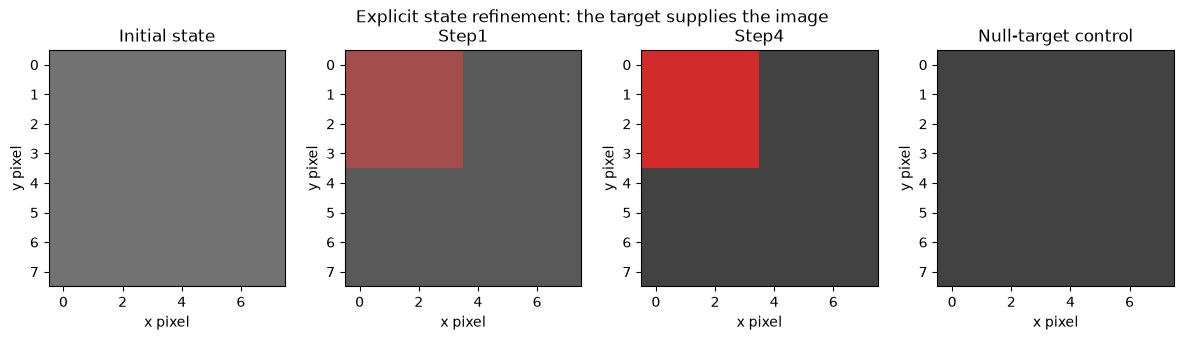

In [5]:
target=np.full((8,8,3),.25);target[:4,:4]=[.85,.15,.15]
initial=np.full_like(target,.45)
state=initial.copy();trajectory=[state.copy()]
for step in range(4):
    state=refinement_step(state,target,.5);trajectory.append(state.copy())
null_state=initial.copy()
for step in range(4):null_state=refinement_step(null_state,np.full_like(target,.25),.5)
print("Patch roundtrip max error:",np.max(np.abs(unpatchify(patchify(target,2),8,8,2)-target)))
utils.image_grid([trajectory[0],trajectory[1],trajectory[4],null_state],["Initial state","Step1","Step4","Null-target control"],"Explicit state refinement: the target supplies the image")
plt.show()

<details><summary>Help - how should I interpret this?</summary>

The square becomes visible only because the update reads an explicit square target. The null-target control stays gray. This image sequence teaches the patch/state plumbing and its control; it establishes no learned denoising capability.

</details>

## Summary of 1️⃣

Patch indices are spatial addresses. A correct image reconstruction and a meaningful conditional generator are different tests; this fixture makes the latter dependency explicit.

# 2️⃣ Conditioning and gated attention

> ##### Learning Objectives
>
> - Implement the visible operations for build the normalization, attention and gated residual operations of a small dit block.
> - Explain the tensor axes and use an independent small-case check.

DiT conditions transformer blocks using time/class information. Adaptive normalization
modulates a normalized token:
$$\operatorname{adaLN}(x;\gamma,\beta)=(1+\gamma)\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta.$$
Here mean and population variance are over feature width, independently per token. A residual
gate gives $x'=x+g\,\operatorname{Attention}(\operatorname{adaLN}(x))W_O$.
With $g=0$, the block is exactly identity. This captures one attention branch; a full DiT also
has a feed-forward branch, learned conditioning and a diffusion prediction head.

### Exercise - implement `adaptive_layer_norm`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Normalize along feature width, then apply scale and shift with NumPy broadcasting.

In [6]:
def adaptive_layer_norm(tokens, scale, shift, eps=1e-6):
    x=np.asarray(tokens,dtype=np.float64)
    normalized=(x-x.mean(axis=-1,keepdims=True))/np.sqrt(x.var(axis=-1,keepdims=True)+eps)
    return (1+np.asarray(scale))*normalized+np.asarray(shift)


tests.test_adaptive_layer_norm(adaptive_layer_norm)

All tests in test_adaptive_layer_norm passed!


<details><summary>Hint</summary>

Use population variance; scale is1+gamma rather than gamma.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_adaptive_layer_norm passed!`.
Constant tokens normalize to zero, then become shift.

</details>

### Exercise - implement `scaled_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Return attention outputs and row-normalized weights. Queries and keys share feature width; values may have another width. Use stable softmax.

In [7]:
def scaled_attention(queries, keys, values):
    scores=np.asarray(queries) @ np.asarray(keys).T / np.sqrt(np.asarray(queries).shape[-1])
    weights=np.exp(scores-scores.max(axis=-1,keepdims=True))
    weights/=weights.sum(axis=-1,keepdims=True)
    return weights @ np.asarray(values),weights


tests.test_scaled_attention(scaled_attention)

All tests in test_scaled_attention passed!


<details><summary>Hint</summary>

Subtract each query row maximum before exponentiating.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_scaled_attention passed!`.
Zero queries yield uniform attention and the arithmetic mean of values.

</details>

### Exercise - implement `dit_attention_block`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Implement one gated self-attention branch using your visible functions. Return token states with the original shape.

In [8]:
def dit_attention_block(tokens, scale, shift, gate, wq, wk, wv, wo):
    conditioned=adaptive_layer_norm(tokens,scale,shift)
    output,_=scaled_attention(conditioned@wq,conditioned@wk,conditioned@wv)
    return np.asarray(tokens)+np.asarray(gate)*(output@wo)


tests.test_dit_attention_block(dit_attention_block)

All tests in test_dit_attention_block passed!


<details><summary>Hint</summary>

Condition q/k/v inputs, then apply the output projection before residual addition.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_dit_attention_block passed!`.
The zero-gate test must pass with nonzero conditioning and weights.

</details>

Zero gate max change: 0.0


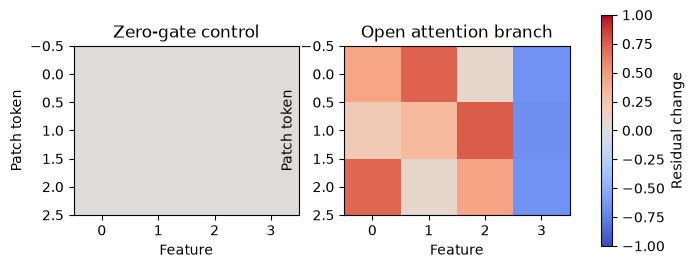

In [9]:
toy_tokens=np.array([[1.,2.,0.,-1.],[0.,1.,3.,-2.],[2.,0.,1.,-1.]])
identity=np.eye(4)
closed=dit_attention_block(toy_tokens,.2,.3,0.,identity,identity,identity,identity)
opened=dit_attention_block(toy_tokens,.2,.3,.5,identity,identity,identity,identity)
print("Zero gate max change:",np.max(np.abs(closed-toy_tokens)))
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,array,name in zip(axes,[closed-toy_tokens,opened-toy_tokens],["Zero-gate control","Open attention branch"]):
    im=ax.imshow(array,cmap='coolwarm',vmin=-1,vmax=1);ax.set(title=name,xlabel="Feature",ylabel="Patch token")
fig.colorbar(im,ax=axes.ravel().tolist(),label="Residual change");plt.show()

<details><summary>Help - how should I interpret this?</summary>

The zero-gate residual is exactly zero. Opening the gate creates a condition-dependent residual change. These activations are algebraic outputs, not an image-quality result or trained denoiser evidence.

</details>

## Summary of 2️⃣

The identities and tensor shapes of a DiT branch are testable before any training. A gate control distinguishes the residual path from the attention branch.

# 3️⃣ Read-only concepts in output space

> ##### Learning Objectives
>
> - Implement the visible operations for compute read-only concept outputs and compare output-space saliency with raw attention.
> - Explain the tensor axes and use an independent small-case check.

ConceptAttention adds concepts that read image and concept states without being read by the
image stream. In a single toy layer, image queries attend image+prompt keys/values; concept
queries attend image+concept keys/values. Sharing those two attention operations in one
unrestricted sequence would let concepts alter the image.

The paper measures similarities between attention output vectors. We implement the per-patch
map $\phi=\operatorname{softmax}_{concept}(O_xO_c^T)$, then average these normalized maps over
layers. Softmax must be over the **concept** axis. Our toy uses scaled dot-product attention
consistently in both streams. The fixed q/k/v tensors are designed to expose the difference
between key-space and output-space maps; they do not demonstrate learned semantics.

### Exercise - implement `readonly_concept_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Return both outputs and both attention matrices. Concept keys/values must never enter the image attention call.

In [10]:
def readonly_concept_attention(image_queries, image_keys, image_values, prompt_keys, prompt_values, concept_queries, concept_keys, concept_values):
    image_output,image_weights=scaled_attention(image_queries,np.concatenate([image_keys,prompt_keys]),np.concatenate([image_values,prompt_values]))
    concept_output,concept_weights=scaled_attention(concept_queries,np.concatenate([image_keys,concept_keys]),np.concatenate([image_values,concept_values]))
    return image_output,concept_output,image_weights,concept_weights


tests.test_readonly_concept_attention(readonly_concept_attention)

All tests in test_readonly_concept_attention passed!


<details><summary>Hint</summary>

Image and concept queries have different key/value pools.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_readonly_concept_attention passed!`.
Changing concept inputs leaves image output bitwise unchanged; tests make the alternative fail.

</details>

### Exercise - implement `output_space_map`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Return `[patches,concepts]` probabilities from attention outputs. Normalize over concepts at each patch.

In [11]:
def output_space_map(image_output, concept_output):
    scores=np.asarray(image_output) @ np.asarray(concept_output).T
    prob=np.exp(scores-scores.max(axis=-1,keepdims=True))
    return prob/prob.sum(axis=-1,keepdims=True)


tests.test_output_space_map(output_space_map)

All tests in test_output_space_map passed!


<details><summary>Hint</summary>

A map is not a raw cross-attention weight.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_output_space_map passed!`.
Two identical concepts receive0.5 at every patch, even if patch magnitudes differ.

</details>

### Exercise - implement `average_layer_maps`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Average already-normalized `[layers,patches,concepts]` maps over layers. Do not average logits then softmax.

In [12]:
def average_layer_maps(layer_maps):
    return np.asarray(layer_maps).mean(axis=0)


tests.test_average_layer_maps(average_layer_maps)

All tests in test_average_layer_maps passed!


<details><summary>Hint</summary>

The layer axis is the first axis.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_average_layer_maps passed!`.
Each output patch row still sums to1.

</details>

### Exercise - implement `raw_key_map`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Construct a clearly labeled key-space baseline: image-key/concept-query dot products, normalized over concepts per patch for the same segmentation decision. This transposed scoring/normalization is a teaching comparator, not the complete raw cross-attention aggregation used in the paper.

In [13]:
def raw_key_map(concept_queries, image_keys):
    scores=np.asarray(image_keys) @ np.asarray(concept_queries).T / np.sqrt(np.asarray(image_keys).shape[-1])
    weights=np.exp(scores-scores.max(axis=-1,keepdims=True))
    return weights/weights.sum(axis=-1,keepdims=True)


tests.test_raw_key_map(raw_key_map)

All tests in test_raw_key_map passed!


<details><summary>Hint</summary>

Use the same output shape and argmax rule as the output-space map.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_raw_key_map passed!`.
Identical zero image keys produce a uniform two-concept map.

</details>

## Summary of 3️⃣

Concepts can be observational probes: a read-only stream measures image representations without injecting new prompt content. The output-space map compares values after attention, not the q/k routing weights.

# 4️⃣ Segmentation, intervention and transfer

> ##### Learning Objectives
>
> - Implement the visible operations for score known segmentation masks and test whether adding concepts changes image outputs.
> - Explain the tensor axes and use an independent small-case check.

The reference image supplies a ground-truth patch mask. Score class0 predictions using
intersection over union $|P\cap G|/|P\cup G|$. State the empty-union convention explicitly:
if both masks are empty, score1. Ties in class scores use NumPy argmax, selecting class0.
A uniform map therefore predicts every patch as foreground and scores only0.25 here.

Forecast the three IoUs before running: output space, raw-key baseline, swapped concept
identity. The swapped control should retain a visually structured map while naming the wrong
region. Sharpness alone is not evidence of correct localization.

### Exercise - implement `segmentation_iou`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 5–10 minutes on this exercise.
> ```

Compute binary-mask IoU with the empty-union convention above.

In [14]:
def segmentation_iou(predicted, truth):
    p=np.asarray(predicted,dtype=bool);g=np.asarray(truth,dtype=bool)
    union=np.count_nonzero(p|g)
    return float(np.count_nonzero(p&g)/union) if union else 1.0


tests.test_segmentation_iou(segmentation_iou)

All tests in test_segmentation_iou passed!


<details><summary>Hint</summary>

Intersection and union count pixels, not mean confidence values.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_segmentation_iou passed!`.
A one-pixel match in a four-pixel union scores0.25.

</details>

IoU output / raw-key / swapped: [1.   0.25 0.  ]


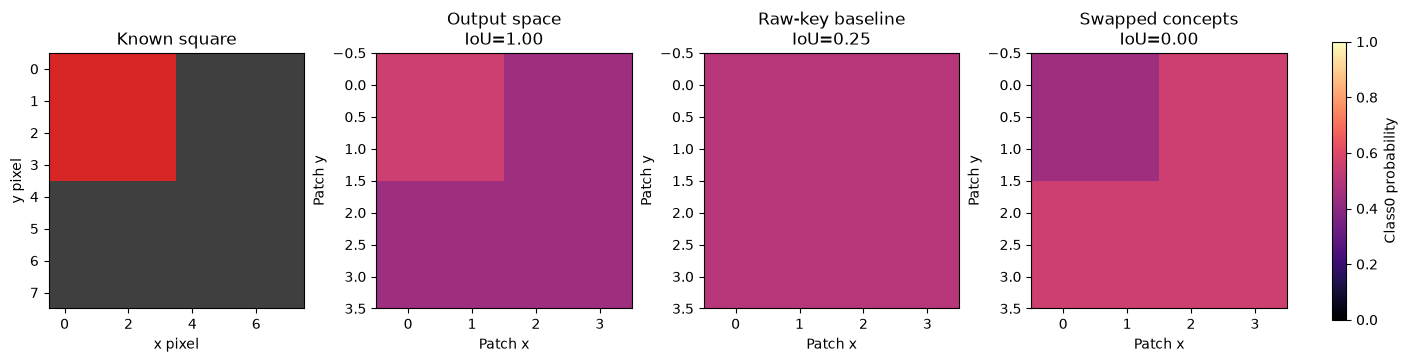

Image output change after concept-query edit: 0.0


In [15]:
truth=np.zeros((4,4),bool);truth[:2,:2]=True
classes=np.where(truth.ravel(),0,1)
image_queries=4*np.eye(2)[classes]
image_keys=np.zeros((16,2));image_values=np.zeros((16,2))
prompt_keys=np.eye(2);prompt_values=np.eye(2)
concept_queries=4*np.eye(2);concept_keys=np.eye(2);concept_values=np.eye(2)
image_out,concept_out,_,_=readonly_concept_attention(image_queries,image_keys,image_values,prompt_keys,prompt_values,concept_queries,concept_keys,concept_values)
map_output=average_layer_maps(np.stack([output_space_map(image_out,concept_out)]*2))
map_raw=raw_key_map(concept_queries,image_keys)
map_swapped=output_space_map(image_out,concept_out[::-1])
conditions=[map_output,map_raw,map_swapped]
ious=[segmentation_iou(m.argmax(-1).reshape(4,4)==0,truth) for m in conditions]
print("IoU output / raw-key / swapped:",np.round(ious,3))
fig,axes=plt.subplots(1,4,figsize=(14,3.5),layout="constrained")
axes[0].imshow(target);axes[0].set(title="Known square",xlabel="x pixel",ylabel="y pixel")
for ax,m,name,score in zip(axes[1:],conditions,["Output space","Raw-key baseline","Swapped concepts"],ious):
    im=ax.imshow(m[:,0].reshape(4,4),vmin=0,vmax=1,cmap='magma');ax.set(title=f"{name}\nIoU={score:.2f}",xlabel="Patch x",ylabel="Patch y")
fig.colorbar(im,ax=axes[1:].ravel().tolist(),label="Class0 probability");plt.show()
changed_concepts=concept_queries*0-5
image_out_again,*_=readonly_concept_attention(image_queries,image_keys,image_values,prompt_keys,prompt_values,changed_concepts,concept_keys,concept_values)
print("Image output change after concept-query edit:",np.max(np.abs(image_out_again-image_out)))

<details><summary>Help - how should I interpret this?</summary>

The actual IoUs are1.00,0.25 and0.00. The raw-key map is uninformative in this constructed organism; output vectors retain the class distinction. Swapped concepts fail despite a sharp map. The concept-query edit changes image outputs by exactly0, verifying the read-only interface. These are analytic properties of the fixture, not a ConceptAttention benchmark result.

</details>

## Try it yourself

Move the square mask to the lower-right quadrant, keeping all key/value parameters fixed.
Predict whether the output-space IoU stays1 and whether the raw-key baseline changes. Then
try a second concept identical to the first. Which tie rule now determines segmentation?
This tests spatial transfer and concept identifiability, rather than a fresh random seed.

Moved-square IoU: 1.0


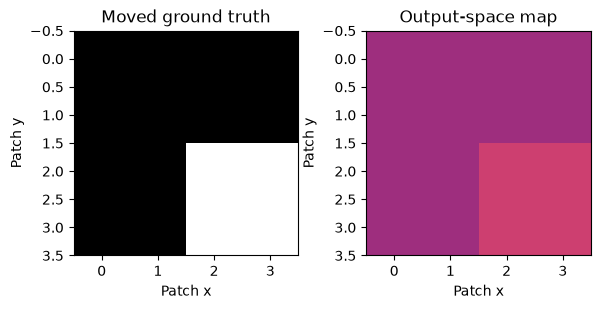

In [16]:
play_truth=np.zeros((4,4),bool);play_truth[2:,2:]=True
play_queries=4*np.eye(2)[np.where(play_truth.ravel(),0,1)]
play_image,play_concept,*_=readonly_concept_attention(play_queries,image_keys,image_values,prompt_keys,prompt_values,concept_queries,concept_keys,concept_values)
play_map=output_space_map(play_image,play_concept)
print("Moved-square IoU:",segmentation_iou(play_map.argmax(-1).reshape(4,4)==0,play_truth))
fig,axes=plt.subplots(1,2,figsize=(6,3))
axes[0].imshow(play_truth,cmap='gray');axes[0].set(title="Moved ground truth",xlabel="Patch x",ylabel="Patch y")
axes[1].imshow(play_map[:,0].reshape(4,4),vmin=0,vmax=1,cmap='magma');axes[1].set(title="Output-space map",xlabel="Patch x",ylabel="Patch y")
fig.tight_layout();plt.show()

## Summary of 4️⃣

Ground-truth masks and wrong-concept controls test localization. Read-only output invariance tests a separate architectural property. Neither alone establishes semantic quality in a trained model.

# ☆ Bonus

## Limits and model bridge

Requirements `image.dit_concept_attention`, `image.sdxl_optional` and `image.flux_optional`
remain explicit. Patchification, adaLN, attention gating, a read-only concept branch,
output-space mapping and mask scoring are taught here. A complete trained DiT, pretrained
ConceptAttention, SDXL and FLUX experiments remain pending; no such model is loaded.

Peebles and Xie replace the diffusion backbone with a transformer over latent patches.
ConceptAttention adds contextual concept states and compares attention output vectors to
localize concepts. Our small layer omits the learned multimodal projections, full concept
residual stream, timestep/layer selection and pretrained image generation. The raw-key
comparator uses matched per-patch concept normalization; do not equate it with the paper's
complete baseline protocol or interpret its planted failure as a general theorem.

For a native follow-on, record exact checkpoint, preprocessing, latent patch geometry,
q/k/v projection locations, concept tokenization, layer/timestep aggregation and fixed mask
annotations. Verify concept-stream edits leave image generation unchanged, and compare
segmentation with wrong concepts, uniform maps and the documented raw-attention baseline.

## Further reading

- [Scalable Diffusion Models with Transformers](https://arxiv.org/abs/2212.09748).
- [ConceptAttention: Diffusion Transformers Learn Highly Interpretable Features](https://arxiv.org/abs/2502.04320).
- [Official ConceptAttention code](https://github.com/helblazer811/ConceptAttention).